In [1]:
import numpy as np
import pandas as pd

ModuleNotFoundError: No module named 'numpy'

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
sns.set(style="darkgrid")

In [ ]:
%matplotlib inline

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Preprocessing

In [ ]:
df=pd.read_excel("ABC_Company.xlsx")

In [ ]:
df.head(10)

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,2023-02-06 00:00:00,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,2023-06-06 00:00:00,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,2023-05-06 00:00:00,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,2023-05-06 00:00:00,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,2023-10-06 00:00:00,231,NaN,5000000.0
5,Amir Johnson,Boston Celtics,90,PF,29,2023-09-06 00:00:00,240,NaN,12000000.0
6,Jordan Mickey,Boston Celtics,55,PF,21,2023-08-06 00:00:00,235,LSU,1170960.0
7,Kelly Olynyk,Boston Celtics,41,C,25,7-0,238,Gonzaga,2165160.0
8,Terry Rozier,Boston Celtics,12,PG,22,2023-02-06 00:00:00,190,Louisville,1824360.0
9,Marcus Smart,Boston Celtics,36,PG,22,2023-04-06 00:00:00,220,Oklahoma State,3431040.0


In [ ]:
df.isnull().sum()

Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College     84
Salary      11
dtype: int64

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    str    
 1   Team      458 non-null    str    
 2   Number    458 non-null    int64  
 3   Position  458 non-null    str    
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    str    
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(1), str(4)
memory usage: 49.4+ KB


In [ ]:
df["Height"]=np.random.randint(150,180,458)

In [ ]:
df.head()

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,173,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,163,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,150,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,154,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,158,231,NaN,5000000.0


In [ ]:
df['Height'].describe()

count    458.000000
mean     164.417031
std        8.729505
min      150.000000
25%      157.000000
50%      164.000000
75%      172.000000
max      179.000000
Name: Height, dtype: float64

# Analysis and Interpretation

## Question 1

### Determine the distribution of employees across each team and calculate the percentage split relative to the total number of employees.

In [ ]:
table=df['Team'].value_counts().reset_index(name='count')

In [ ]:
table=pd.DataFrame(table)

In [ ]:
table['Percentage']=(table['count']/len(df))*100
df1=pd.DataFrame(table)
df1

,Team,count,Percentage
0,New Orleans Pelicans,19,4.148472
1,Memphis Grizzlies,18,3.930131
2,New York Knicks,16,3.493450
3,Milwaukee Bucks,16,3.493450
4,Utah Jazz,16,3.493450
5,Boston Celtics,15,3.275109
6,Brooklyn Nets,15,3.275109
7,Philadelphia 76ers,15,3.275109
8,Toronto Raptors,15,3.275109
9,Golden State Warriors,15,3.275109


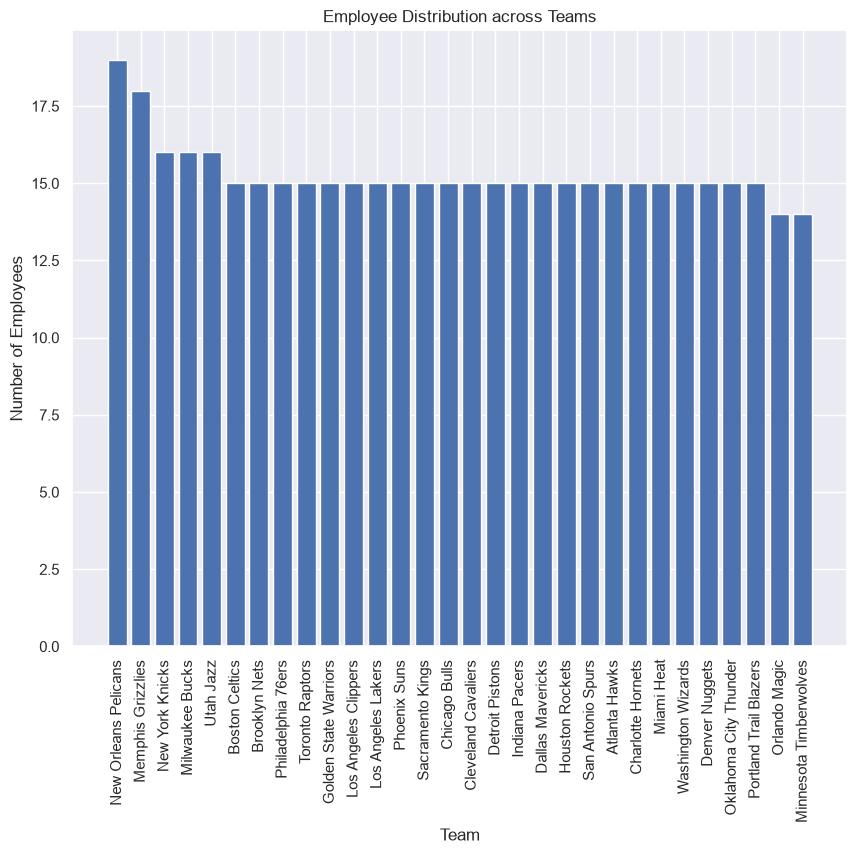

In [ ]:
plt.figure(figsize=(10,8))
plt.bar(df1['Team'],df1['count'])
plt.title("Employee Distribution across Teams")
plt.xlabel("Team")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)
plt.show()

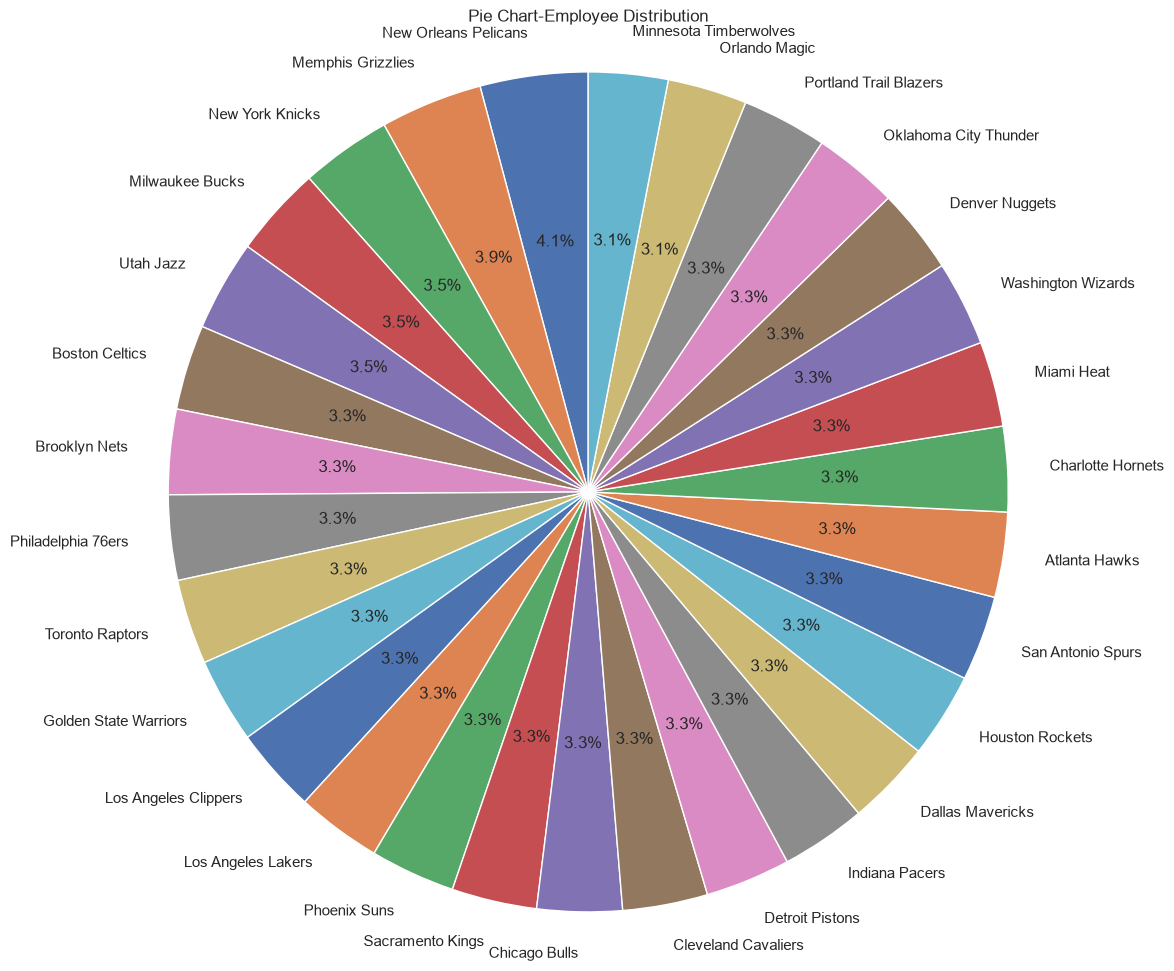

In [ ]:
plt.figure(figsize=(14,12))
plt.pie(df1['count'],labels=df1['Team'], autopct='%.1f%%',shadow=False,startangle=90)
plt.title('Pie Chart-Employee Distribution')
plt.axis('equal')  
plt.show()

OR

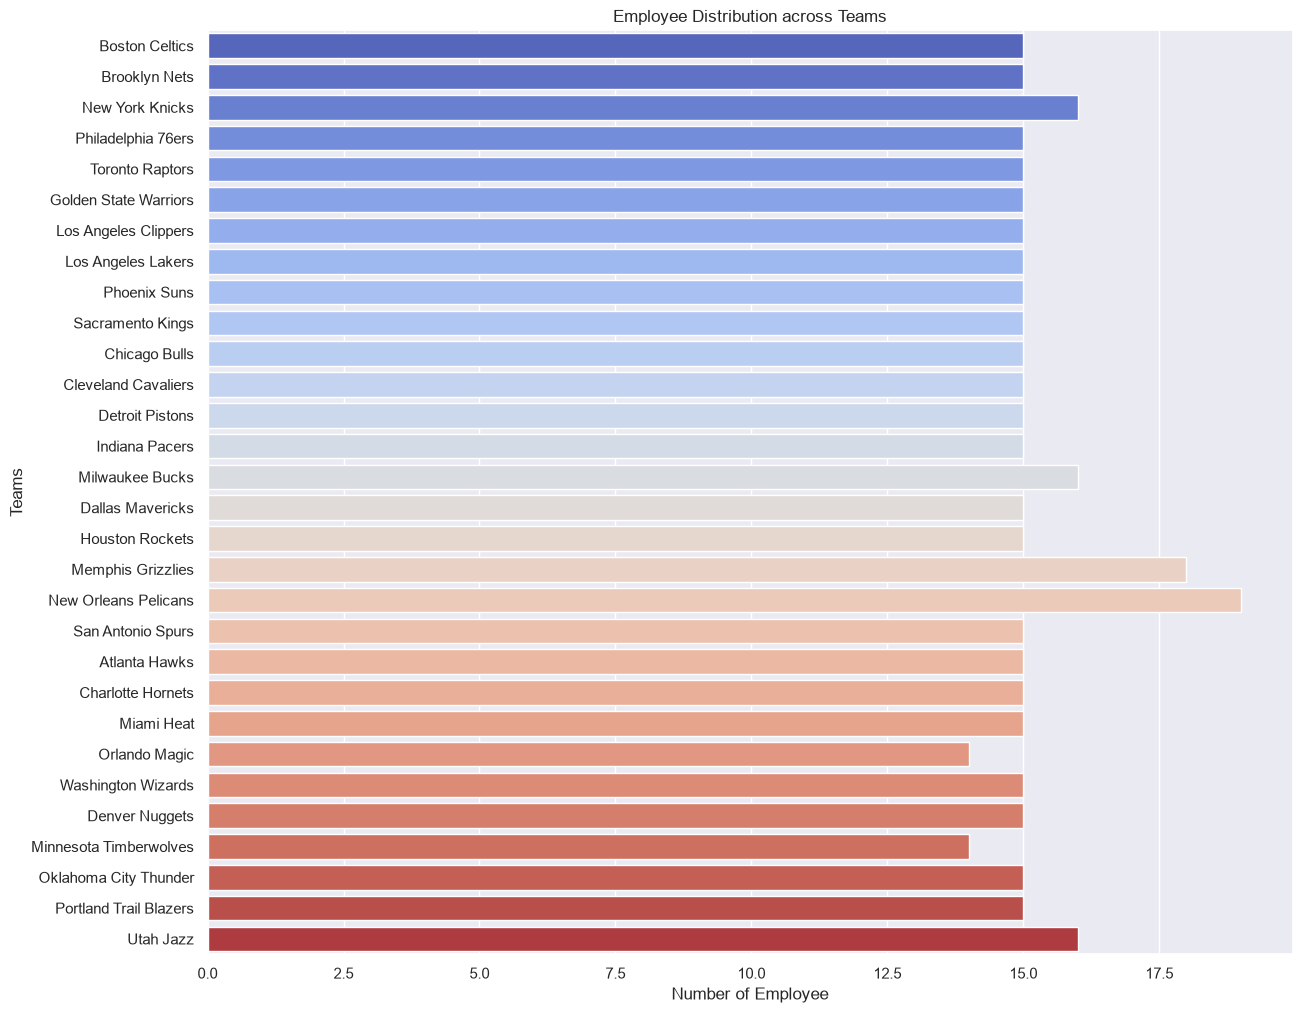

In [ ]:
plt.figure(figsize=(14,12))
sns.countplot(y='Team',data=df,palette='coolwarm')
plt.title("Employee Distribution across Teams")
plt.ylabel("Teams")
plt.xlabel('Number of Employee')
plt.show()

## Question 2

### Segregate employees based on their positions within the company.

In [ ]:
table=df['Position'].value_counts().reset_index(name='count')

In [ ]:
df2=pd.DataFrame(table)
df2

,Position,count
0,SG,102
1,PF,100
2,PG,92
3,SF,85
4,C,79


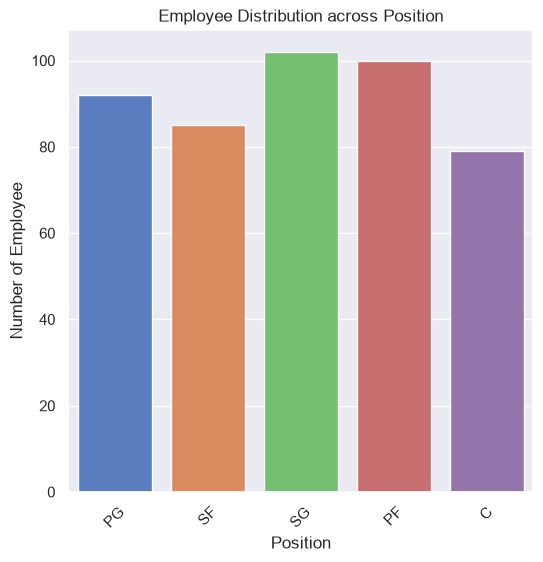

In [ ]:
plt.figure(figsize=(6,6))
sns.countplot(x='Position',data=df,palette='muted')
plt.title("Employee Distribution across Position")
plt.xlabel("Position")
plt.ylabel('Number of Employee')
plt.xticks(rotation=45)
plt.show()

OR

In [ ]:
counts = df['Position'].value_counts()
print(counts)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


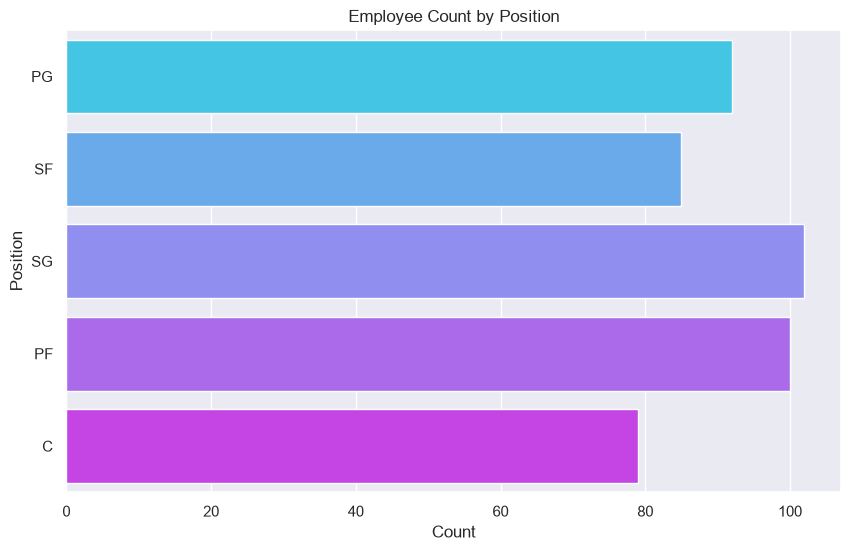

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='Position', palette='cool')
plt.title('Employee Count by Position')
plt.xlabel('Count')
plt.ylabel('Position')
plt.show()

## Question 3

### Identify the predominant age group among employees.

In [ ]:
counts=df['Age'].value_counts()
counts

Age
24    47
25    46
27    41
23    41
26    36
28    31
30    31
29    28
22    26
31    22
21    19
20    19
33    14
32    13
34    10
36    10
35     9
37     4
38     4
40     3
39     2
19     2
Name: count, dtype: int64

In [ ]:
df['Age'].mode()

0    24
Name: Age, dtype: int64

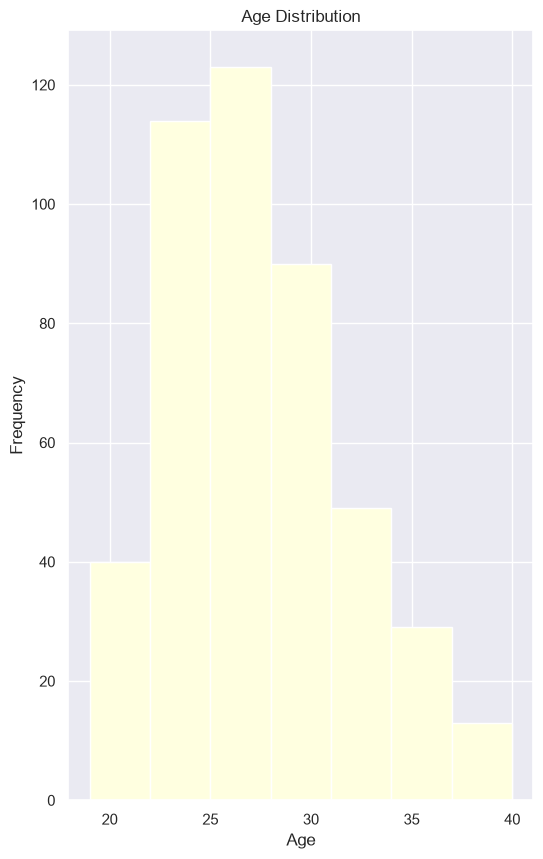

In [ ]:
plt.figure(figsize = (6,10))
plt.hist(df['Age'],bins=7,color='lightyellow')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

OR

<Figure size 600x1000 with 0 Axes>

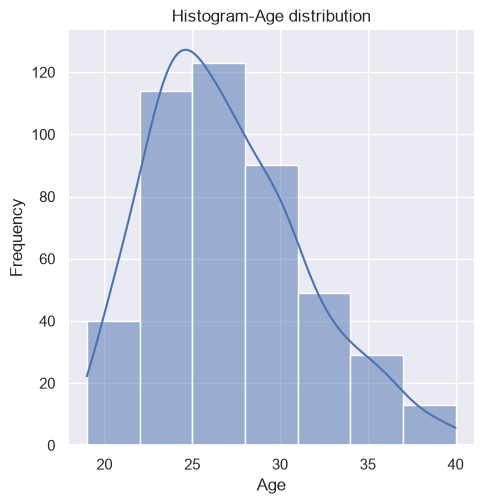

In [ ]:
plt.figure(figsize = (6,10))
sns.displot(df['Age'],bins=7,kde=True)
plt.title("Histogram-Age distribution")
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

## Question 4

### Discover which team and position have the highest salary expenditure.

In [ ]:
df4=df.dropna(subset=['Team','Position','Salary'])

In [ ]:
df4[['Team','Position','Salary']].isnull().sum()

Team        0
Position    0
Salary      0
dtype: int64

In [ ]:
df5 = df.groupby(['Team', 'Position'])['Salary'].sum().reset_index()
df5.head()

,Team,Position,Salary
0,Atlanta Hawks,C,22756250.0
1,Atlanta Hawks,PF,23952268.0
2,Atlanta Hawks,PG,9763400.0
3,Atlanta Hawks,SF,6000000.0
4,Atlanta Hawks,SG,10431032.0


In [ ]:
team_salary = df.groupby('Team')['Salary'].sum().sort_values(ascending=False)
sal_by_tm=pd.DataFrame(team_salary)

In [ ]:
print(sal_by_tm[sal_by_tm['Salary']==sal_by_tm['Salary'].max()])

                          Salary
Team                            
Cleveland Cavaliers  106988689.0


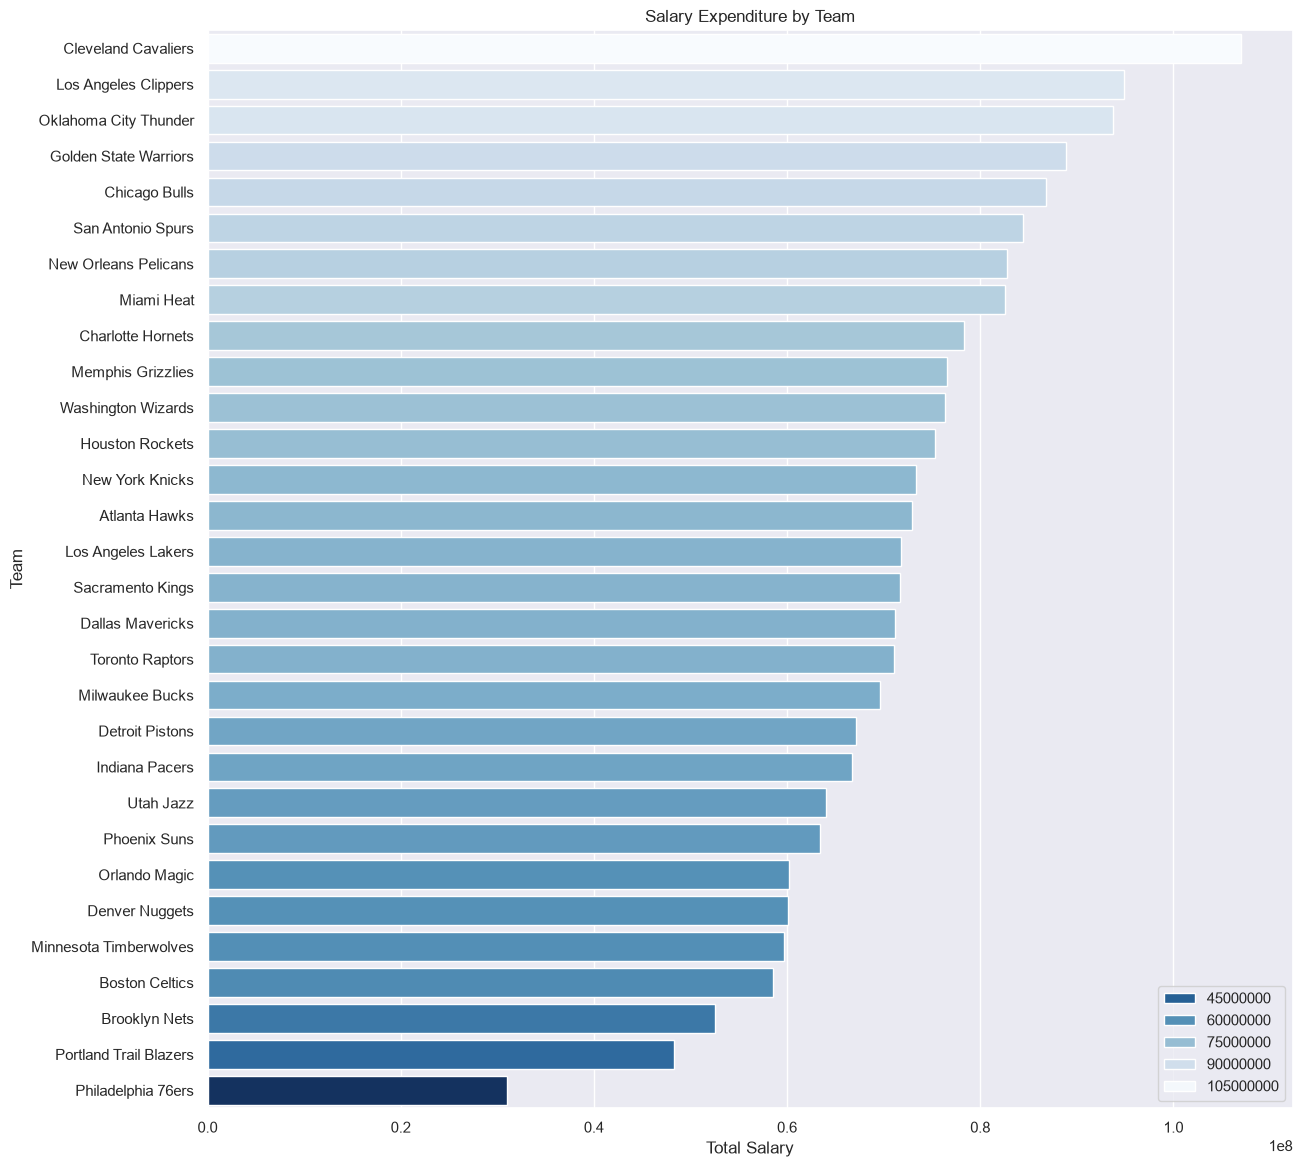

In [ ]:
plt.figure(figsize = (14,14))
sns.barplot(x=team_salary.values, y=team_salary.index,hue=team_salary.values, palette='Blues_r')
plt.title('Salary Expenditure by Team')
plt.xlabel('Total Salary')
plt.show()

In [ ]:
position_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False)
sal_by_pos=pd.DataFrame(position_salary)

In [ ]:
print(sal_by_pos[sal_by_pos['Salary']==sal_by_pos['Salary'].max()])

               Salary
Position             
C         466377332.0


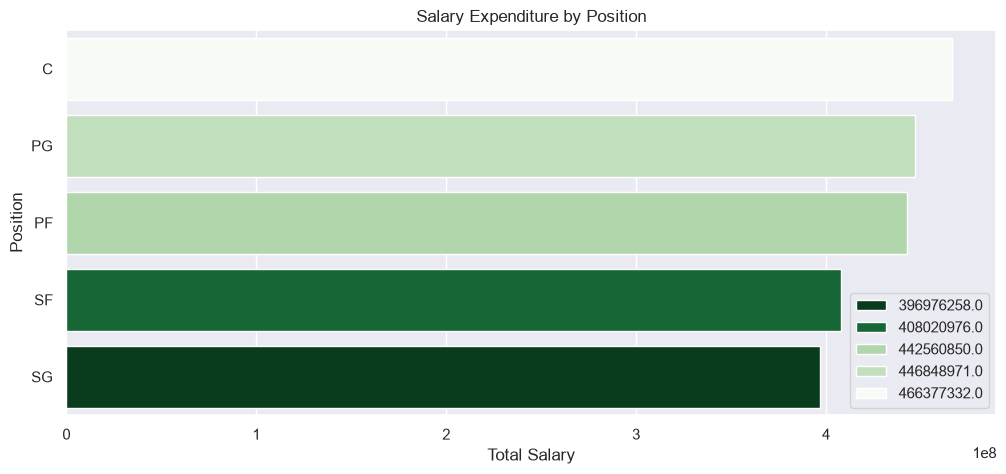

In [ ]:
plt.figure(figsize = (12,5))
sns.barplot(x=position_salary.values, y=position_salary.index,hue=position_salary.values, palette='Greens_r')
plt.title('Salary Expenditure by Position')
plt.xlabel('Total Salary')
plt.show()

OR

In [ ]:
position_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False).reset_index(name='salary_sum')
data=pd.DataFrame(position_salary)

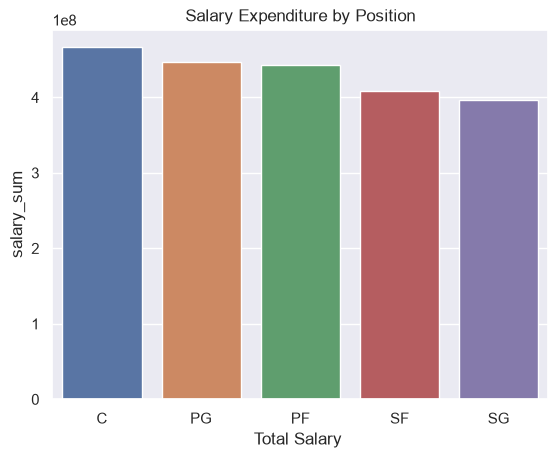

In [ ]:
sns.barplot(x="Position", y="salary_sum",data=data,hue="Position")
plt.title('Salary Expenditure by Position')
plt.xlabel('Total Salary ')
plt.show()

In [ ]:
print(df5[df5['Salary'] == df5['Salary'].max()])

                  Team Position      Salary
67  Los Angeles Lakers       SF  31866445.0


<Figure size 1400x1400 with 0 Axes>

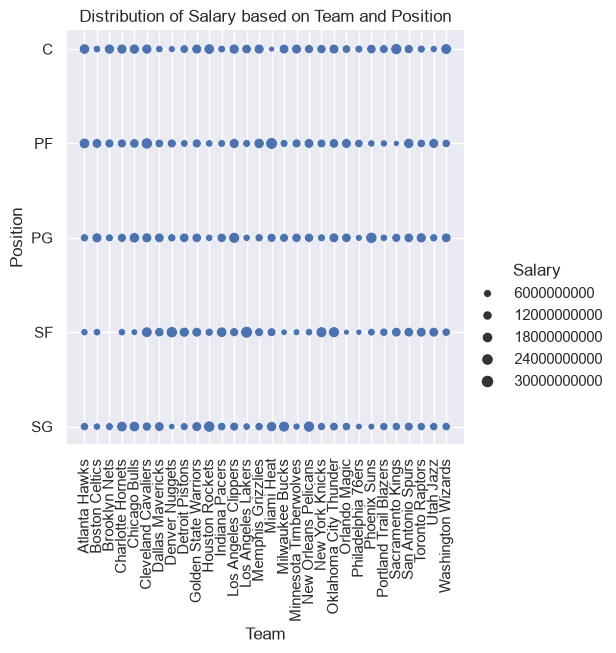

In [ ]:
plt.figure(figsize = (14,14))
sns.relplot(x='Team',y='Position',size=df5['Salary']*1000, data=df5, palette='bright',kind="scatter");
plt.title('Distribution of Salary based on Team and Position')
plt.xlabel('Team')
plt.ylabel('Position')
plt.xticks(rotation=90)
plt.show()

## Question 5

### Investigate if there's any correlation between age and salary, and represent it visually.

In [ ]:
df6=df.dropna(subset=['Age','Salary'])

In [ ]:
df6[['Age','Salary']].isnull().sum()

Age       0
Salary    0
dtype: int64

In [ ]:
df7=df6[['Age','Salary']]
df7.head()

,Age,Salary
0,25,7730337.0
1,25,6796117.0
3,22,1148640.0
4,29,5000000.0
5,29,12000000.0


In [ ]:
corr=df7.corr()
corr

,Age,Salary
Age,1.000000,0.214009
Salary,0.214009,1.000000


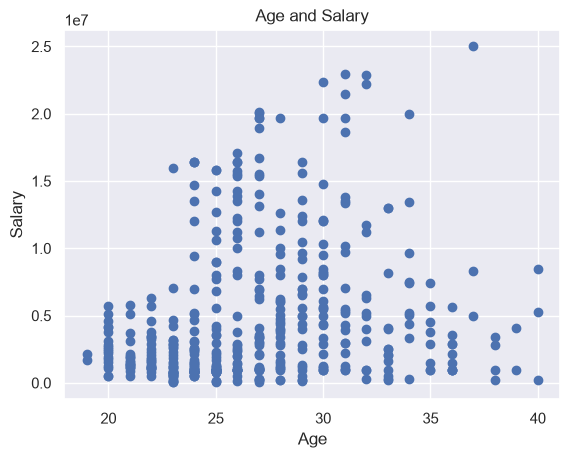

In [ ]:
plt.scatter(df7["Age"], df7["Salary"])
plt.title("Age and Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

OR

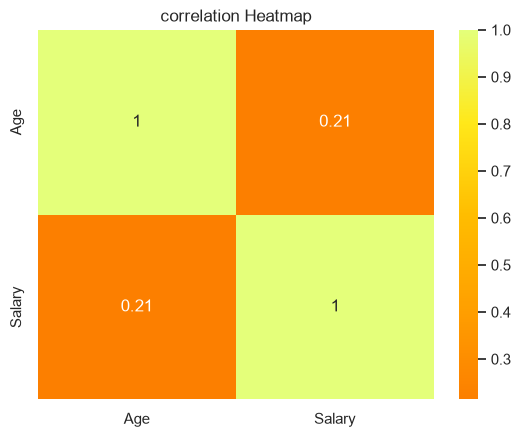

In [ ]:
sns.heatmap(corr,annot=True,cmap='Wistia_r')
plt.title('correlation Heatmap')
plt.show()